<a href="https://colab.research.google.com/github/faiq191/244107020214-machine-learning/blob/main/JS08/JS08_Assignment01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Step 1: Import libraries and load the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv('CC_Customer_Dataset.csv')
display(df.head())

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
# Step 2: Preprocess and Scale the data
columns_to_drop = [col for col in ['Sl_No', 'Customer Key', 'Cust_ID'] if col in df.columns]
X = df.drop(columns=columns_to_drop)
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
# Step 3: Build and fit the Agglomerative Clustering model
n_clusters = 3
model = AgglomerativeClustering(n_clusters=n_clusters)
labels = model.fit_predict(X_scaled)
df['Cluster'] = labels

In [5]:
# Step 4: Display evaluation metrics
sil_score = silhouette_score(X_scaled, labels)
dbi_score = davies_bouldin_score(X_scaled, labels)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies-Bouldin Index (DBI): {dbi_score:.4f}")

Silhouette Score: 0.5148
Davies-Bouldin Index (DBI): 0.6810


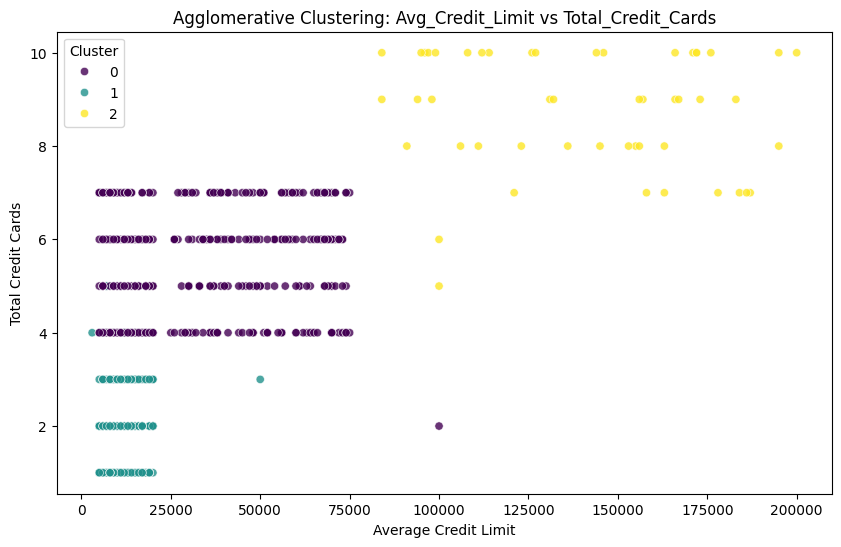

In [7]:
# Step 5: Visualize the clustered configurations
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='viridis',
    data=df,
    alpha=0.8
)
plt.title('Agglomerative Clustering: Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.show()